# Laboratori 5 · Ushtrime Shtesë — Përshkimi i grafeve dhe pema përfshirëse minimum, në kod

> Laboratori kryesor i tregoi algoritmet në lëvizje: labirintin me BFS dhe DFS, Kruskal-in dhe Prim-in.
> Këtu i shkruani **vetë**, funksion pas funksioni, dhe çdo qelizë `kontrollo(...)` ju tregon nëse janë të sakta.
> Vetëm Python i thjeshtë: `deque`, `heapq`, fjalorë dhe bashkësi. Nuk kërkon Pygame.

| # | Ushtrimi | Çfarë mësoni |
|:-:|---|---|
| 1 | BFS: largesat dhe prindërit | radha FIFO, pse BFS jep shtegun më të shkurtër |
| 2 | Shtegu nga `prind` | rindërtimi i shtegut |
| 3 | Komponentet e lidhura | BFS nga çdo kulm i pavizituar |
| 4 | Grafi dyanësor | ngjyrosja me BFS, cikli tek |
| 5 | DFS me kohët | koha e zbulimit dhe e mbarimit, vetia e kllapave |
| 6 | Bashkësitë disjunkte | `gjej` me kompresim, `bashko` sipas rangut |
| 7 | Kruskal | brinjët sipas peshës + bashkësitë disjunkte |
| 8 | Prim | pema që rritet + radha me prioritet |

## Kujtues teorik

**Paraqitja.** Një graf i padrejtuar jepet si **listë fqinjësie**: `G = {"A": ["B", "C"], ...}`, ku çdo brinjë
$\{u, v\}$ shfaqet te të dy kulmet. Fqinjët janë në rend alfabetik, që të gjithë të marrim të njëjtat rezultate.
Një graf me peshë jepet si listë brinjësh `E = [("A", "B", 6), ...]`.

| Algoritmi | Struktura | Çfarë jep | Koha |
|---|---|---|---|
| **BFS** | radhë (FIFO) | largesat në numër brinjësh nga $s$, pema e shtigjeve më të shkurtra | $O(V + E)$ |
| **DFS** | stivë / rekursion | koha e zbulimit $d[v]$ dhe e mbarimit $f[v]$ | $O(V + E)$ |
| **Kruskal** | renditje + bashkësi disjunkte | pema përfshirëse minimum | $O(E \log E)$ |
| **Prim** | radhë me prioritet (heap) | pema përfshirëse minimum | $O(E \log V)$ |

**Pse BFS jep largesën më të shkurtër.** BFS i nxjerr kulmet sipas largesës: të gjithë ata në largesë $k$
dalin para çdo kulmi në largesë $k+1$. Kur kulmi $v$ zbulohet nga $u$, $d[v] = d[u] + 1$ dhe nuk ndryshon më.

**Vetia e kllapave (DFS).** Për çdo dy kulme, intervalet $[d[u], f[u]]$ dhe $[d[v], f[v]]$ janë ose **njëri
brenda tjetrit** (njëri është pasardhës i tjetrit në pemën e DFS) ose **të ndara** — kurrë të mbivendosura pjesërisht.

**Vetia e prerjes (Kruskal dhe Prim).** Brinja më e lehtë që kalon një prerje $(S, V \setminus S)$ i përket
një peme përfshirëse minimum. Prim e zbaton te prerja *pema / pjesa tjetër*; Kruskal te prerja që ndan
komponenten e njërit skaj.

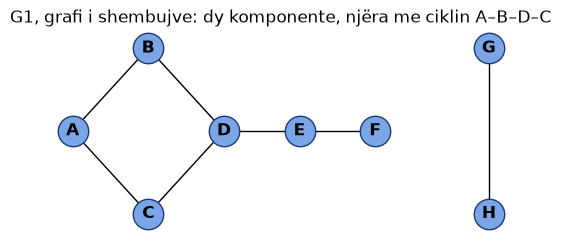

In [1]:
# ── Mjeti i kontrollit ──────────────────────────────────────────────
# Ekzekutojeni këtë qelizë një herë, në fillim. Pas çdo ushtrimi, qeliza
# "kontrollo(...)" teston funksionin tuaj dhe ju tregon nëse është gati.

def kontrollo(titulli, testet):
    try:
        testet()
    except NotImplementedError:
        print(f"⏳ {titulli}: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.")
    except AssertionError as e:
        print(f"✗ {titulli}: {e}")
    except Exception as e:
        print(f"✗ {titulli}: kodi u ndal me gabim  {type(e).__name__}: {e}")
    else:
        print(f"✓ {titulli}: të gjitha testet kaluan!")


from collections import deque
from itertools import combinations
import heapq
import random


def nga_brinjet(V, E):
    # Lista e fqinjësisë së një grafi të padrejtuar, fqinjët në rend alfabetik.
    G = {v: [] for v in V}
    for brinja in E:
        u, v = brinja[0], brinja[1]
        G[u].append(v)
        G[v].append(u)
    return {v: sorted(set(fq)) for v, fq in G.items()}


def pasi_plotesohet(fn):
    # Ekzekuton një demonstrim që varet nga funksionet tuaja.
    try:
        fn()
    except NotImplementedError:
        print("⏳ Ky rezultat shfaqet pasi të plotësoni ushtrimin e mësipërm.")


# Grafi i shembujve: dy pjesë, njëra me një cikël.
G1 = nga_brinjet(
    "ABCDEFGH",
    [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D"), ("D", "E"), ("E", "F"), ("G", "H")],
)

import matplotlib.pyplot as plt
import networkx as nx

_, ax = plt.subplots(figsize=(6.5, 2.6))
H = nx.Graph([(u, v) for u in G1 for v in G1[u]])
POS_G1 = {"A": (0, 1), "B": (1, 2), "C": (1, 0), "D": (2, 1), "E": (3, 1), "F": (4, 1), "G": (5.5, 2), "H": (5.5, 0)}
nx.draw_networkx(H, POS_G1, ax=ax, node_color="#7aa6e8", edgecolors="#1f3b70", node_size=480, font_weight="bold")
ax.set_title("G1, grafi i shembujve: dy komponente, njëra me ciklin A–B–D–C")
ax.axis("off")
plt.show()

## Ushtrimi 1 — BFS: largesat dhe prindërit

**Detyra:** `bfs(G, s)` kthen dy fjalorë `(dist, prind)`:
- `dist[v]` = numri i brinjëve të shtegut më të shkurtër nga `s` te `v`;
- `prind[v]` = kulmi nga i cili u zbulua `v` (`prind[s] = None`).

Përfshini **vetëm** kulmet e arritshme nga `s`. Përdorni `deque`: `append` për të futur, `popleft` për të nxjerrë.

*Kontrolli nuk e krahason me një zgjidhje të fshehur: ai verifikon vetitë që e bëjnë një `dist` të saktë —
çdo kulm ka një prind një hap më afër, dhe asnjë brinjë nuk kapërcen më shumë se një nivel.*

In [2]:
def bfs(G, s):
    # PLOTESO: dist[s] = 0, prind[s] = None; nxirrni nga radha, zbuloni fqinjët e pazbuluar
    raise NotImplementedError

In [3]:
def _kontrollo_bfs(G, s, dist, prind):
    assert dist.get(s) == 0 and prind.get(s) is None, "dist[s] duhet 0 dhe prind[s] None"
    assert set(dist) == set(prind), "dist dhe prind duhet të kenë të njëjtat kulme"
    for u in dist:
        for v in G[u]:
            assert v in dist, f"{v} është fqinj i {u}, pra i arritshëm, por mungon"
            assert abs(dist[u] - dist[v]) <= 1, f"brinja {u}–{v} kapërcen nga niveli {dist[u]} te {dist[v]}"
    for v, p in prind.items():
        if v != s:
            assert v in G[p], f"prind[{v}] = {p}, por {p}–{v} nuk është brinjë"
            assert dist[v] == dist[p] + 1, f"dist[{v}] duhet të jetë dist[{p}] + 1"


def _testet():
    dist, prind = bfs(G1, "A")
    assert dist == {"A": 0, "B": 1, "C": 1, "D": 2, "E": 3, "F": 4}, f"largesat nga A: {dist}"
    assert "G" not in dist, "G dhe H nuk arrihen nga A: mos i përfshini"
    _kontrollo_bfs(G1, "A", dist, prind)
    rng = random.Random(4)
    for _ in range(200):
        n = rng.randint(1, 9)
        V = [str(i) for i in range(n)]
        E = [(u, v) for u, v in combinations(V, 2) if rng.random() < 0.3]
        G = nga_brinjet(V, E)
        s = rng.choice(V)
        _kontrollo_bfs(G, s, *bfs(G, s))

kontrollo("Ushtrimi 1 — BFS", _testet)

⏳ Ushtrimi 1 — BFS: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Ushtrimi 2 — Shtegu nga `prind`

**Detyra:** `shtegu(prind, s, t)` kthen listën e kulmeve të shtegut më të shkurtër nga `s` te `t`, duke ndjekur
`prind` nga `t` mbrapsht dhe duke e përmbysur në fund. Nëse `t` nuk u arrit (nuk është te `prind`), ktheni `None`.

In [4]:
def shtegu(prind, s, t):
    # PLOTESO: nga t, ndiqni prind derisa të arrini s; pastaj përmbyseni listën
    raise NotImplementedError

In [5]:
def _testet():
    dist, prind = bfs(G1, "A")
    assert shtegu(prind, "A", "A") == ["A"], "shtegu nga A te vetja është [A]"
    P = shtegu(prind, "A", "F")
    assert P[0] == "A" and P[-1] == "F" and len(P) == dist["F"] + 1, f"shtegu A → F ka 5 kulme: {P}"
    assert all(b in G1[a] for a, b in zip(P, P[1:])), f"{P} përdor një brinjë që nuk ekziston"
    assert shtegu(prind, "A", "H") is None, "H nuk arrihet nga A: ktheni None"

kontrollo("Ushtrimi 2 — Shtegu", _testet)

⏳ Ushtrimi 2 — Shtegu: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


In [6]:
def _demo():
    # Nivelet e BFS nga A: çdo kolonë është një largesë.
    dist, prind = bfs(G1, "A")
    pos = {}
    for niveli in range(max(dist.values()) + 1):
        ne_nivel = sorted(v for v in dist if dist[v] == niveli)
        for i, v in enumerate(ne_nivel):
            pos[v] = (niveli, -i)
    H = nx.Graph([(u, v) for u in dist for v in G1[u] if v in dist])
    _, ax = plt.subplots(figsize=(6, 2.6))
    pema = [(prind[v], v) for v in dist if prind[v]]
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#c7c9d1")
    nx.draw_networkx_edges(H, pos, edgelist=pema, ax=ax, edge_color="#b5179e", width=2.5)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color="#7aa6e8", edgecolors="#1f3b70", node_size=480)
    nx.draw_networkx_labels(H, pos, ax=ax, font_weight="bold")
    ax.set_title("BFS nga A: nivelet dhe pema e shtigjeve më të shkurtra")
    ax.axis("off")
    plt.show()

pasi_plotesohet(_demo)

⏳ Ky rezultat shfaqet pasi të plotësoni ushtrimin e mësipërm.


## Ushtrimi 3 — Komponentet e lidhura

Një **komponente e lidhur** është një grup maksimal kulmesh ku çdo kulm arrin çdo kulm tjetër.

**Detyra:** `komponentet(G)` kthen listën e komponenteve, secila si `set`. Kaloni kulmet në rend alfabetik;
për çdo kulm që ende s'është në asnjë komponente, një `bfs` prej tij jep gjithë komponenten e tij.

In [7]:
def komponentet(G):
    # PLOTESO: për çdo kulm të pavizituar, set(bfs(G, v)[0]) është një komponente e re
    raise NotImplementedError

In [8]:
def _testet():
    assert komponentet(G1) == [{"A", "B", "C", "D", "E", "F"}, {"G", "H"}], f"G1 ka dy komponente: {komponentet(G1)}"
    assert komponentet(nga_brinjet("XYZ", [])) == [{"X"}, {"Y"}, {"Z"}], "pa brinjë: çdo kulm është komponente më vete"
    rng = random.Random(7)
    for _ in range(150):
        V = [str(i) for i in range(rng.randint(1, 9))]
        G = nga_brinjet(V, [(u, v) for u, v in combinations(V, 2) if rng.random() < 0.25])
        K = komponentet(G)
        assert sorted(v for k in K for v in k) == sorted(V), "çdo kulm duhet të jetë në saktësisht një komponente"
        ku = {v: i for i, k in enumerate(K) for v in k}
        assert all(ku[u] == ku[v] for u in G for v in G[u]), "një brinjë lidh dy komponente të ndryshme"
        assert all(set(bfs(G, next(iter(k)))[0]) == k for k in K), "një komponente nuk është e lidhur ose nuk është maksimale"

kontrollo("Ushtrimi 3 — Komponentet", _testet)

⏳ Ushtrimi 3 — Komponentet: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Ushtrimi 4 — Grafi dyanësor

Një graf është **dyanësor** kur kulmet ndahen në dy pjesë dhe çdo brinjë lidh dy pjesët. Teorema: një graf
është dyanësor **atëherë dhe vetëm atëherë** kur nuk ka cikël me gjatësi tek.

**Detyra:** `dyanesor(G)` kthen një ngjyrosje `{kulm: 0 ose 1}` ku çdo brinjë ka skajet me ngjyra të ndryshme,
ose `None` nëse nuk ekziston. Ideja: në çdo komponente, ngjyra = barazia e largesës BFS (`dist[v] % 2`); pastaj
kontrolloni nëse ndonjë brinjë ka të dy skajet me të njëjtën ngjyrë — ajo brinjë mbyll një cikël tek.

In [9]:
def dyanesor(G):
    # PLOTESO: ngjyra[v] = dist[v] % 2 në çdo komponente; None nëse një brinjë lidh dy ngjyra të njëjta
    raise NotImplementedError

In [10]:
def _cikel(n):
    V = [str(i) for i in range(n)]
    return nga_brinjet(V, [(V[i], V[(i + 1) % n]) for i in range(n)])


def _testet():
    for n in (4, 6, 8):
        c = dyanesor(_cikel(n))
        assert c is not None, f"cikli me {n} kulme (çift) është dyanësor"
        assert all(c[u] != c[v] for u in _cikel(n) for v in _cikel(n)[u]), "një brinjë ka të dy skajet me të njëjtën ngjyrë"
    for n in (3, 5, 7):
        assert dyanesor(_cikel(n)) is None, f"cikli me {n} kulme (tek) nuk është dyanësor"
    c = dyanesor(G1)
    assert c is not None and set(c) == set(G1), "G1 ka vetëm ciklin A–B–D–C–A me 4 brinjë: është dyanësor, me ngjyrë për çdo kulm"
    assert all(c[u] != c[v] for u in G1 for v in G1[u]), "një brinjë e G1 ka të dy skajet me të njëjtën ngjyrë"
    G_trekendesh = nga_brinjet("ABCDEFGH", [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D"), ("D", "E"), ("E", "F"), ("G", "H"), ("A", "D")])
    assert dyanesor(G_trekendesh) is None, "me brinjën A–D lind trekëndëshi A–B–D: cikël tek, pra jo dyanësor"

kontrollo("Ushtrimi 4 — Dyanësor", _testet)

⏳ Ushtrimi 4 — Dyanësor: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Ushtrimi 5 — DFS me kohët

DFS zbulon një kulm, viziton rekursivisht çdo fqinj të pazbuluar, dhe **mbaron** kulmin kur s'ka më ku të shkojë.
Një orë e përbashkët shënon kohën: `d[v]` kur zbulohet, `f[v]` kur mbaron. Ora nis nga 1 dhe rritet me 1 në çdo ngjarje.

**Detyra:** `dfs_kohet(G)` kthen `(d, f)`. Nisni DFS nga kulmet në rend alfabetik (nga çdo kulm ende i pazbuluar),
dhe vizitoni fqinjët sipas rendit të listës.

In [11]:
def dfs_kohet(G):
    # PLOTESO: një funksion i brendshëm rekursiv viziton(u); ora rritet në zbulim dhe në mbarim
    raise NotImplementedError

In [12]:
def _testet():
    d, f = dfs_kohet(G1)
    assert d == {"A": 1, "B": 2, "D": 3, "C": 4, "E": 6, "F": 7, "G": 13, "H": 14}, f"kohët e zbulimit: {d}"
    assert f == {"C": 5, "F": 8, "E": 9, "D": 10, "B": 11, "A": 12, "H": 15, "G": 16}, f"kohët e mbarimit: {f}"
    rng = random.Random(11)
    for _ in range(150):
        V = [str(i) for i in range(rng.randint(1, 8))]
        G = nga_brinjet(V, [(u, v) for u, v in combinations(V, 2) if rng.random() < 0.35])
        d, f = dfs_kohet(G)
        assert sorted(list(d.values()) + list(f.values())) == list(range(1, 2 * len(V) + 1)), \
            "çdo kohë nga 1 deri në 2|V| përdoret saktësisht një herë"
        for u, v in combinations(V, 2):
            a, b = (d[u], f[u]), (d[v], f[v])
            brenda = (a[0] < b[0] < b[1] < a[1]) or (b[0] < a[0] < a[1] < b[1])
            ndara = a[1] < b[0] or b[1] < a[0]
            assert brenda or ndara, f"intervalet e {u} {a} dhe {v} {b} mbivendosen pjesërisht: shkel vetinë e kllapave"

kontrollo("Ushtrimi 5 — DFS", _testet)

⏳ Ushtrimi 5 — DFS: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Ushtrimi 6 — Bashkësitë disjunkte (union-find)

Kruskal pyet shumë herë: *a janë $u$ dhe $v$ në të njëjtën komponente?* Bashkësitë disjunkte e bëjnë këtë
pothuajse në kohë konstante. Çdo bashkësi është një pemë; rrënja e saj e përfaqëson.

- `gjej(x)`: ndiq prindërit deri te rrënja, pastaj vendos **çdo** kulm të rrugës të tregojë drejt rrënjës
  (*kompresimi i rrugës*).
- `bashko(a, b)`: gjej rrënjët; nëse janë të njëjta ktheni `False`; përndryshe vendosni rrënjën me **rang** më të
  vogël nën tjetrën (në barazim, `b`-në nën `a`-në dhe rritni rangun e `a`-së), dhe ktheni `True`.

In [13]:
class BashkesiDisjunkte:
    def __init__(self, V):
        self.prind = {v: v for v in V}
        self.rang = {v: 0 for v in V}

    def gjej(self, x):
        # PLOTESO: rrënja, pastaj çdo kulm i rrugës merr si prind rrënjën
        raise NotImplementedError

    def bashko(self, a, b):
        # PLOTESO: bashkimi sipas rangut; False nëse janë tashmë bashkë
        raise NotImplementedError

In [14]:
def _testet():
    B = BashkesiDisjunkte("abcdefgh")
    assert B.bashko("a", "b") and B.bashko("c", "d") and B.bashko("a", "c"), "bashkime të reja kthejnë True"
    assert B.bashko("b", "d") is False, "b dhe d janë tashmë bashkë: False"
    assert B.gjej("d") == B.gjej("a") != B.gjej("e"), "a, b, c, d në një bashkësi; e më vete"
    assert B.rang[B.gjej("a")] == 2, "dy bashkime me rang të barabartë → rangu i rrënjës 2"
    B.gjej("d")
    assert B.prind["d"] == B.gjej("a"), "pas gjej(d), d duhet të tregojë drejt rrënjës (kompresimi)"
    rng = random.Random(3)
    for _ in range(50):
        n = rng.randint(2, 64)
        B = BashkesiDisjunkte(range(n))
        for _ in range(n):
            B.bashko(rng.randrange(n), rng.randrange(n))
        assert max(B.rang.values()) <= n.bit_length() - 1, "me bashkim sipas rangut, rangu nuk kalon log₂ n"

kontrollo("Ushtrimi 6 — Bashkësitë disjunkte", _testet)

⏳ Ushtrimi 6 — Bashkësitë disjunkte: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Ushtrimi 7 — Kruskal

**Detyra:** `kruskal(V, E)` kthen `(pema, pesha)`: listën e brinjëve të zgjedhura `(u, v, w)` dhe peshën totale.
Renditni brinjët sipas peshës (në barazim, sipas rendit të listës — `sorted` me `key` e ruan atë), dhe pranoni
një brinjë vetëm nëse `bashko(u, v)` kthen `True`. Në një graf jo të lidhur, kjo jep një **pyll** minimum.

*Kontrolli përdor `komponentet` tuaj të Ushtrimit 3, prandaj plotësoni më parë atë.*

In [15]:
# Grafi i Punës në Klasë, Problemi 2 i laboratorit kryesor
V_KLASA = "ABCDE"
E_KLASA = [("A", "B", 6), ("A", "C", 1), ("B", "C", 5), ("B", "D", 3), ("C", "D", 4), ("C", "E", 2), ("D", "E", 8)]


def kruskal(V, E):
    # PLOTESO: sorted(E, key=...) dhe BashkesiDisjunkte(V)
    raise NotImplementedError

In [16]:
def _pema_minimale(V, E):
    # Me forcë brutale: pylli përfshirës me peshën më të vogël, nga të gjitha nënbashkësitë e brinjëve.
    k = len(komponentet(nga_brinjet(V, E)))
    me_e_mira = None
    for zgjedhja in combinations(E, len(V) - k):
        if len(komponentet(nga_brinjet(V, zgjedhja))) == k:
            w = sum(b[2] for b in zgjedhja)
            me_e_mira = w if me_e_mira is None else min(me_e_mira, w)
    return me_e_mira


def _testet():
    pema, pesha = kruskal(V_KLASA, E_KLASA)
    assert pesha == 10 and len(pema) == 4, f"Problemi 2: 4 brinjë me peshë 10, u morën {len(pema)} me {pesha}"
    assert [(u, v) for u, v, _ in pema] == [("A", "C"), ("C", "E"), ("B", "D"), ("C", "D")], f"rendi: {pema}"
    rng = random.Random(5)
    for _ in range(60):
        V = [str(i) for i in range(rng.randint(2, 6))]
        E = [(u, v, rng.randint(1, 9)) for u, v in combinations(V, 2) if rng.random() < 0.6]
        pema, pesha = kruskal(V, E)
        assert pesha == sum(w for *_, w in pema), "pesha duhet të jetë shuma e brinjëve të pemës"
        k = len(komponentet(nga_brinjet(V, E)))
        assert len(pema) == len(V) - k, f"një pyll përfshirës ka |V| − {k} brinjë"
        assert len(komponentet(nga_brinjet(V, pema))) == k, "pema ka cikël ose nuk i lidh komponentet"
        assert pesha == _pema_minimale(V, E), f"pesha {pesha} nuk është minimale për {E}"

kontrollo("Ushtrimi 7 — Kruskal", _testet)

⏳ Ushtrimi 7 — Kruskal: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Ushtrimi 8 — Prim

**Detyra:** `prim(V, E, s)` kthen `(pema, pesha)` duke e rritur pemën nga `s`. Mbani në një **heap** brinjët
që dalin nga pema si `(w, u, v)`, ku `u` është në pemë. Në çdo hap nxirrni më të lehtën; nëse `v` është tashmë
në pemë, hidheni; përndryshe shtoni `(u, v, w)` dhe futni në heap brinjët e reja të `v`. Supozoni grafin të lidhur.

In [17]:
def prim(V, E, s):
    # PLOTESO: G me (fqinj, peshë); heap me (w, u, v); bashkësia e kulmeve në pemë
    raise NotImplementedError

In [18]:
def _testet():
    pema, pesha = prim(V_KLASA, E_KLASA, "A")
    assert pesha == 10, f"Problemi 3: Prim nga A jep peshën 10, u mor {pesha}"
    assert [(u, v) for u, v, _ in pema] == [("A", "C"), ("C", "E"), ("C", "D"), ("D", "B")], f"rendi nga A: {pema}"
    assert prim(V_KLASA, E_KLASA, "E")[1] == 10, "nga E pesha është po ashtu 10"
    rng = random.Random(9)
    for _ in range(60):
        V = [str(i) for i in range(rng.randint(2, 6))]
        E = [(V[i], V[rng.randrange(i)], rng.randint(1, 9)) for i in range(1, len(V))]
        E += [(u, v, rng.randint(1, 9)) for u, v in combinations(V, 2) if rng.random() < 0.4]
        pema, pesha = prim(V, E, rng.choice(V))
        assert len(pema) == len(V) - 1, "pema e një grafi të lidhur ka |V| − 1 brinjë"
        assert pesha == kruskal(V, E)[1] == _pema_minimale(V, E), "Prim dhe Kruskal duhet të japin të njëjtën peshë minimale"

kontrollo("Ushtrimi 8 — Prim", _testet)

⏳ Ushtrimi 8 — Prim: ende pa plotësuar — zëvendësoni `raise NotImplementedError` me kodin tuaj.


## Punë në Klasë

**Problemi 1 — BFS me dorë.** Ekzekutoni `bfs(G1, "C")` me laps e letër. Plotësoni tabelën me radhën pas çdo
nxjerrjeje, dhe `dist` e `prind` të çdo kulmi të zbuluar. Pse G dhe H nuk shfaqen?

| Nxirret | Radha pas | Zbulohen (me `dist`, `prind`) |
|:-:|---|---|
| C | | |
| … | | |

**Problemi 2 — Kohët e DFS.** Vizatoni intervalet $[d, f]$ të Ushtrimit 5 si kllapa mbi një bosht kohe.
Cilat kulme janë pasardhës të B-së në pemën e DFS? Si e lexoni këtë vetëm nga intervalet?

**Problemi 3 — Bashkësitë disjunkte.** Nisni me {1}, {2}, …, {8} dhe bëni `bashko(1,2)`, `bashko(3,4)`,
`bashko(1,3)`, `bashko(5,6)`, `bashko(7,8)`, `bashko(5,7)`, `bashko(1,5)`. Vizatoni pyllin dhe rangjet pas çdo
hapi. Sa e lartë është pema në fund? Po pa bashkimin sipas rangut, në rastin më të keq?

**Problemi 4 — Kruskal apo Prim?** Për një graf të plotë me 1 000 kulme, sa brinjë ka? Krahasoni $O(E \log E)$
të Kruskal-it me $O(E \log V)$ të Prim-it me heap. Po për një rrjet rrugor me 10 000 kulme dhe 30 000 brinjë?

## Pyetje Reflektuese

1. BFS gjen shtegun me **më pak brinjë**. Pse nuk mjafton kur brinjët kanë pesha? Ndërtoni një graf me tre kulme
   ku shtegu me më pak brinjë nuk është më i lehti.
2. Në `dyanesor`, pse mjafton të kontrollohen brinjët **pas** ngjyrosjes me barazinë e largesës? Çfarë cikli mbyll
   një brinjë me të dy skajet në të njëjtin nivel?
3. Pa kompresimin e rrugës dhe pa bashkimin sipas rangut, sa mund të zgjasë një `gjej`? Jepni një varg bashkimesh
   që e bën pemën një varg të gjatë.
4. Kruskal-i dhe Prim-i mund të zgjedhin **brinjë të ndryshme** dhe prapë të japin të njëjtën peshë. Kur është
   pema përfshirëse minimum **e vetme**?